# Dataset exploration

Cityscapes-sequence and KITTI-STEP both live under `/data/video-segmentation`. They share the 19 Cityscapes train IDs (`0–18`); `255` is ignore.

Cityscapes labels one frame in each 30-frame snippet. KITTI-STEP labels every frame, and its panoptic PNGs also carry track IDs for person and car.

In [1]:
%matplotlib inline

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from cityscapesscripts.helpers.labels import trainId2label
from PIL import Image

DATA_ROOT = Path("/data/video-segmentation")
CITYSCAPES = DATA_ROOT / "cityscapes"
KITTISTEP = DATA_ROOT / "kittistep"

TRAIN_IDS = list(range(19))
CLASS_NAMES = [trainId2label[i].name for i in TRAIN_IDS] + ["ignore"]
CLASS_COLORS = np.array([trainId2label[i].color for i in TRAIN_IDS] + [(0, 0, 0)], dtype=np.uint8)


def colorize(train_ids: np.ndarray) -> np.ndarray:
    """Map a train-ID label image to Cityscapes RGB colors. 255 stays black."""
    lut = np.zeros((256, 3), dtype=np.uint8)
    lut[TRAIN_IDS] = CLASS_COLORS[:-1]
    return lut[train_ids]


def read_rgb(path: Path) -> np.ndarray:
    with Image.open(path) as image:
        return np.array(image.convert("RGB"))


def read_label(path: Path) -> np.ndarray:
    with Image.open(path) as image:
        return np.array(image, dtype=np.uint8)


## What is on disk

Cityscapes frames are `leftImg8bit_sequence/{split}/{city}/{city}_{seq}_{frame}_leftImg8bit.png`. The label we train on is `gtFine/{split}/{city}/..._gtFine_labelTrainIds.png`. KITTI frames and panoptic maps share the relative path `{split}/{seq}/{frame}.png`.

In [2]:
def count_pngs(root: Path) -> int:
    return sum(1 for _ in root.rglob("*.png")) if root.is_dir() else 0


print(f"{'Cityscapes':<28} {'frames':>8} {'labelTrainIds':>14} {'cities':>8}")
for split in ("train", "val", "test"):
    frame_root = CITYSCAPES / "leftImg8bit_sequence" / split
    label_root = CITYSCAPES / "gtFine" / split
    n_frames = count_pngs(frame_root)
    n_labels = len(list(label_root.glob("*/*_labelTrainIds.png"))) if label_root.is_dir() else 0
    n_cities = sum(1 for p in frame_root.iterdir() if p.is_dir()) if frame_root.is_dir() else 0
    print(f"{split:<28} {n_frames:8d} {n_labels:14d} {n_cities:8d}")

missing_frames = []
for split in ("train", "val"):
    for label in (CITYSCAPES / "gtFine" / split).glob("*/*_labelTrainIds.png"):
        frame = Path(
            str(label)
            .replace("/gtFine/", "/leftImg8bit_sequence/")
            .replace("_gtFine_labelTrainIds.png", "_leftImg8bit.png")
        )
        if not frame.exists():
            missing_frames.append(label)
print("labeled frames with no RGB image:", len(missing_frames))

print()
print(f"{'KITTI-STEP':<28} {'images':>8} {'panoptic':>10} {'seqs':>6}")
for split in ("train", "val"):
    image_root = KITTISTEP / "images" / split
    panoptic_root = KITTISTEP / "panoptic_maps" / split
    images = {p.relative_to(image_root) for p in image_root.glob("*/*.png")}
    panoptic = {p.relative_to(panoptic_root) for p in panoptic_root.glob("*/*.png")}
    print(f"{split:<28} {len(images):8d} {len(panoptic):10d} {sum(1 for p in image_root.iterdir() if p.is_dir()):6d}")
    print(
        f"  names in both trees: {len(images & panoptic)}  "
        f"only images: {len(images - panoptic)}  only panoptic: {len(panoptic - images)}"
    )


Cityscapes                     frames  labelTrainIds   cities
train                           89250           2975       18
val                             15000            500        3
test                                0           1525        0
labeled frames with no RGB image: 0

KITTI-STEP                     images   panoptic   seqs
train                            5027       5027     12
  names in both trees: 5027  only images: 0  only panoptic: 0
val                              2981       2981      9
  names in both trees: 2981  only images: 0  only panoptic: 0


## One Cityscapes snippet

A snippet is 30 frames. The labeled frame is the 20th: offsets `-19` through `+10` around its absolute frame number. Timestamps are nanoseconds, and the first one is often `0`. Most cities step by 58.8 ms (17 Hz). The example is the first training label with both a person and a car; that snippet's clock advances in jumps of two or three of those steps.

label: gtFine/train/aachen/aachen_000000_000019_gtFine_labelTrainIds.png
snippet frames missing: none


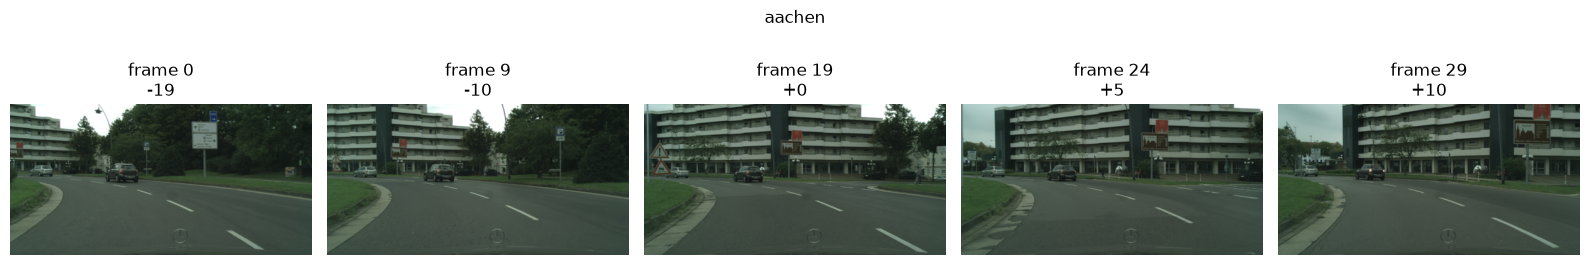

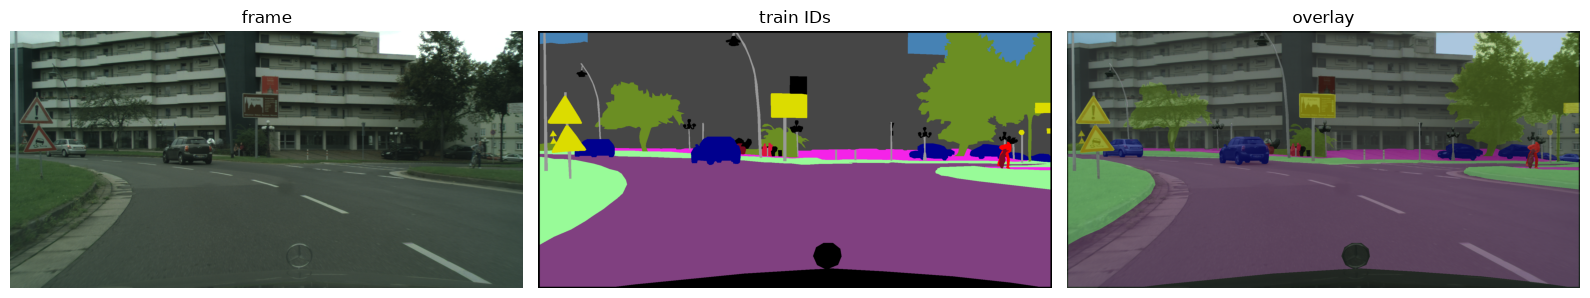

label shape (1024, 2048), dtype uint8, ids [0, 1, 2, 5, 7, 8, 9, 10, 11, 12, 13, 18, 255]
timestamp steps: min 117.9 ms, median 117.9 ms, max 176.8 ms (28 steps, 1 missing)


In [3]:
def cityscapes_frame(label_path: Path) -> Path:
    return Path(
        str(label_path)
        .replace("/gtFine/", "/leftImg8bit_sequence/")
        .replace("_gtFine_labelTrainIds.png", "_leftImg8bit.png")
    )


def parse_frame_name(path: Path) -> tuple[str, str, int]:
    city, seq, frame, *_ = path.name.split("_")
    return city, seq, int(frame)


def snippet_paths(frame_path: Path) -> list[Path]:
    city, seq, frame = parse_frame_name(frame_path)
    return [
        frame_path.with_name(f"{city}_{seq}_{frame + offset:06d}_leftImg8bit.png")
        for offset in range(-19, 11)
    ]


def timestamp_ns(frame_path: Path) -> int:
    stamp = Path(
        str(frame_path)
        .replace("/leftImg8bit_sequence/", "/timestamp_sequence/")
        .replace("_leftImg8bit.png", "_timestamp.txt")
    )
    return int(stamp.read_text().strip())


def first_label_with(split: str, *train_ids: int) -> Path:
    wanted = set(train_ids)
    for path in sorted((CITYSCAPES / "gtFine" / split).glob("*/*_labelTrainIds.png")):
        present = set(np.unique(read_label(path)).tolist())
        if wanted <= present:
            return path
    raise FileNotFoundError(f"no {split} label contains {wanted}")


label_path = first_label_with("train", 11, 13)  # person and car
frame_path = cityscapes_frame(label_path)
frames = snippet_paths(frame_path)
missing = [p.name for p in frames if not p.exists()]
print("label:", label_path.relative_to(CITYSCAPES))
print("snippet frames missing:", missing or "none")

shown = [-19, -10, 0, 5, 10]
fig, axes = plt.subplots(1, len(shown), figsize=(16, 3.2))
_, _, labeled_no = parse_frame_name(frame_path)
for ax, offset in zip(axes, shown):
    ax.imshow(Image.open(frames[offset + 19]).resize((480, 240)))
    ax.set_title(f"frame {labeled_no + offset}\n{offset:+d}")
    ax.axis("off")
fig.suptitle(frame_path.parent.name)
fig.tight_layout()
plt.show()

image = read_rgb(frame_path)
label = read_label(label_path)
overlay = (0.55 * image + 0.45 * colorize(label)).astype(np.uint8)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, picture, title in zip(axes, (image, colorize(label), overlay), ("frame", "train IDs", "overlay")):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()

stamps = np.array([timestamp_ns(p) for p in frames], dtype=np.int64)
present = stamps > 0
intervals = np.diff(stamps)
intervals = intervals[present[1:] & present[:-1]]
print(f"label shape {label.shape}, dtype {label.dtype}, ids {np.unique(label).tolist()}")
print(
    f"timestamp steps: min {intervals.min() / 1e6:.1f} ms, "
    f"median {np.median(intervals) / 1e6:.1f} ms, "
    f"max {intervals.max() / 1e6:.1f} ms "
    f"({intervals.size} steps, {int((~present).sum())} missing)"
)


## One KITTI-STEP frame

Images vary slightly in size, so a batch needs a shared crop or resize. The panoptic PNG stores the train ID in R and the track ID in `G * 256 + B`. Track IDs are only assigned for person (`11`) and car (`13`), and they stay stable inside one sequence.

split       seq   frames            w x h
train      0000      154         1242x375
train      0001      447         1242x375
train      0003      144         1242x375
train      0004      314         1242x375
train      0005      297         1242x375
train      0009      803         1242x375
train      0011      373         1242x375
train      0012       78         1242x375
train      0015      376         1224x370
train      0017      145         1224x370
train      0019     1059         1238x374
train      0020      837         1241x376
val        0002      233         1242x375
val        0006      270         1242x375


val        0007      800         1242x375
val        0008      390         1242x375
val        0010      294         1242x375
val        0013      340         1242x375
val        0014      106         1224x370
val        0016      209         1224x370
val        0018      339         1238x374

frames by size:
  1242 x 375: 4937
  1238 x 374: 1398
  1241 x 376: 837
  1224 x 370: 836

example: images/train/0000/000138.png
  person: tracks [13], pixels with no track 0
  car: tracks [6, 7, 8, 10, 11, 12, 14, 15], pixels with no track 5728


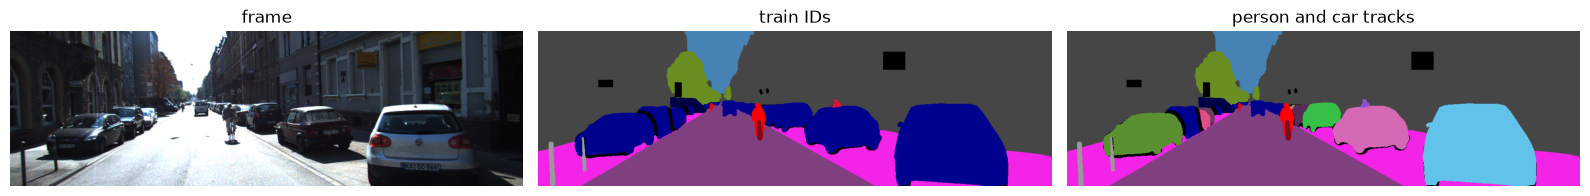

In [4]:
def decode_panoptic(path: Path) -> tuple[np.ndarray, np.ndarray]:
    panoptic = read_label(path)
    semantic = panoptic[..., 0]
    instance = panoptic[..., 1].astype(np.int32) * 256 + panoptic[..., 2].astype(np.int32)
    return semantic, instance


print(f"{'split':<8} {'seq':>6} {'frames':>8} {'w x h':>16}")
size_counts: Counter[tuple[int, int]] = Counter()
for split in ("train", "val"):
    for seq in sorted(p for p in (KITTISTEP / "images" / split).iterdir() if p.is_dir()):
        frames = sorted(seq.glob("*.png"))
        sizes = Counter()
        for path in frames:
            with Image.open(path) as image:
                sizes[image.size] += 1
        size_counts.update(sizes)
        size_text = ", ".join(f"{w}x{h}" for w, h in sorted(sizes))
        print(f"{split:<8} {seq.name:>6} {len(frames):8d} {size_text:>16}")

print()
print("frames by size:")
for (width, height), count in sorted(size_counts.items(), key=lambda item: -item[1]):
    print(f"  {width} x {height}: {count}")


def first_tracked_frame(split: str = "train") -> Path:
    root = KITTISTEP / "panoptic_maps" / split
    for seq in sorted(p for p in root.iterdir() if p.is_dir()):
        for path in sorted(seq.glob("*.png")):
            semantic, instance = decode_panoptic(path)
            has_person = ((semantic == 11) & (instance > 0)).any()
            has_car = ((semantic == 13) & (instance > 0)).any()
            if has_person and has_car:
                return path
    raise FileNotFoundError("no frame has both a person track and a car track")


panoptic_path = first_tracked_frame()
semantic, instance = decode_panoptic(panoptic_path)
image_path = KITTISTEP / "images" / panoptic_path.relative_to(KITTISTEP / "panoptic_maps")
print()
print("example:", image_path.relative_to(KITTISTEP))
for train_id, name in ((11, "person"), (13, "car")):
    tracks = np.unique(instance[(semantic == train_id) & (instance > 0)])
    unlabeled = int(((semantic == train_id) & (instance == 0)).sum())
    print(f"  {name}: tracks {tracks.tolist() or 'none'}, pixels with no track {unlabeled}")

tracked = instance > 0
palette = np.zeros((int(instance.max()) + 1, 3), dtype=np.uint8)
rng = np.random.default_rng(0)
palette[1:] = rng.integers(40, 255, size=(len(palette) - 1, 3), dtype=np.uint8)
instance_color = colorize(semantic)
instance_color[tracked] = palette[instance[tracked]]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, picture, title in zip(
    axes,
    (read_rgb(image_path), colorize(semantic), instance_color),
    ("frame", "train IDs", "person and car tracks"),
):
    ax.imshow(picture)
    ax.set_title(title)
    ax.axis("off")
fig.tight_layout()
plt.show()


## Class balance

Pixel share below includes ignore. Road, building, and vegetation dominate Cityscapes. KITTI-STEP puts more pixels on vegetation, sky, and terrain. The rare classes (rider, motorcycle, traffic light, large vehicles) are each well under one percent, which is why an unweighted loss under-learns them.

cityscapes train


  500/2975
  1000/2975
  1500/2975
  2000/2975
  2500/2975
  2975/2975
  shapes: {(1024, 2048): 2975}
cityscapes val
  500/500
  shapes: {(1024, 2048): 500}
kitti train
  500/5027
  1000/5027
  1500/5027
  2000/5027
  2500/5027
  3000/5027
  3500/5027
  4000/5027
  4500/5027
  5000/5027
  5027/5027
  shapes: {(375, 1242): 2610, (370, 1224): 521, (374, 1238): 1059, (376, 1241): 837}
kitti val
  500/2981
  1000/2981
  1500/2981
  2000/2981
  2500/2981
  2981/2981
  shapes: {(375, 1242): 2327, (370, 1224): 315, (374, 1238): 339}

  id class             cityscapes train    cityscapes val       kitti train         kitti val
   0 road                        32.63%            32.92%            18.96%            20.04%
   1 sidewalk                     5.39%             4.73%             7.04%             7.35%
   2 building                    20.19%            19.16%            15.88%             9.69%
   3 wall                         0.58%             0.64%             0.45%             0.2

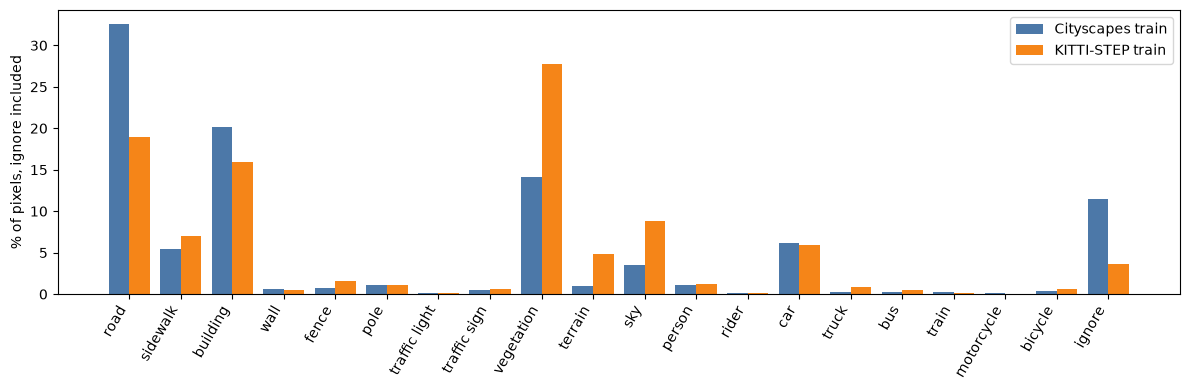

In [5]:
def histogram(paths: list[Path], semantic_channel: bool, every: int = 500) -> tuple[np.ndarray, Counter]:
    counts = np.zeros(256, dtype=np.int64)
    shapes: Counter[tuple[int, ...]] = Counter()
    for index, path in enumerate(paths, start=1):
        array = read_label(path)
        label = array[..., 0] if semantic_channel else array
        shapes[tuple(label.shape)] += 1
        counts += np.bincount(label.reshape(-1), minlength=256)
        if index % every == 0 or index == len(paths):
            print(f"  {index}/{len(paths)}", flush=True)
    return counts, shapes


def collect(root: Path, pattern: str) -> list[Path]:
    return sorted(root.glob(pattern))


splits = {
    "cityscapes train": collect(CITYSCAPES / "gtFine" / "train", "*/*_labelTrainIds.png"),
    "cityscapes val": collect(CITYSCAPES / "gtFine" / "val", "*/*_labelTrainIds.png"),
    "kitti train": collect(KITTISTEP / "panoptic_maps" / "train", "*/*.png"),
    "kitti val": collect(KITTISTEP / "panoptic_maps" / "val", "*/*.png"),
}

histograms = {}
for name, paths in splits.items():
    print(name)
    counts, shapes = histogram(paths, semantic_channel=name.startswith("kitti"))
    histograms[name] = counts
    print("  shapes:", dict(shapes))

ids = np.array(TRAIN_IDS + [255])
shares = {name: counts[ids] / counts[ids].sum() * 100 for name, counts in histograms.items()}

print()
header = f"{'id':>4} {'class':<16}" + "".join(f"{name:>18}" for name in shares)
print(header)
for row, train_id, class_name in zip(np.stack(list(shares.values()), axis=1), ids, CLASS_NAMES):
    values = "".join(f"{value:17.2f}%" for value in row)
    print(f"{train_id:4d} {class_name:<16}{values}")

fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(CLASS_NAMES))
width = 0.4
ax.bar(x - width / 2, shares["cityscapes train"], width, label="Cityscapes train", color="#4c78a8")
ax.bar(x + width / 2, shares["kitti train"], width, label="KITTI-STEP train", color="#f58518")
ax.set_xticks(x, CLASS_NAMES, rotation=60, ha="right")
ax.set_ylabel("% of pixels, ignore included")
ax.legend()
fig.tight_layout()
plt.show()
